# 1. Problem — locating chemical radicals


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`projections`，shape `(1, 40, 1200)`，dtype `<f8`：Noisy signed receiver spectra in arbitrary receiver units; axes batch, gradient direction, homogeneous field.；`magnetic_field_G`，shape `(1, 1200)`，dtype `<f8`：Homogeneous field sampling coordinates in G, increasing along the spectral axis.；`gradients_G_cm`，shape `(1, 2, 40)`，dtype `<f8`：Applied gradient components in G/cm; component order $x,y$, followed by projection order.；`reference_spectra`，shape `(1, 2, 1200)`，dtype `<f8`：TAM and TEMPO response templates in arbitrary receiver units per relative spin amount, sampled on the same field axis.。未知量为TAM/TEMPO双组分100×100相对自旋密度。

获取模型：密度场按梯度位置平移真实光谱模板并空间积分，加入独立高斯接收噪声。

如何恢复：src.solvers.reconstruct/primal_dual及本地频域正向/伴随。

GT与评价：GT为生成观测前定义的模拟物理未知量，不是恢复结果。

已有实验和图：cell3完整混合谱与模板/方向；5独立物理检查；7主解；9四图含真值/上游/新解、消融、偏差/噪声与稳健性。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留3个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。

<!-- inverse-evidence-audit:20261026:end -->


This active review reconstructs both complete two-dimensional TAM/TEMPO relative spin-density fields. The observations are **author-defined simulated measurements**, generated by the unchanged author example using real response templates. They are not experimental spatial images. The benchmark evaluates actual analytical truth and independent known-noise consistency, rather than only agreement with a source reconstruction.

A gradient shifts each radical's response according to position:

$$
s_p(B)=\sum_{j=1}^{2}\int_\Omega u_j(x,y)
h_j(B+g_{xp}x+g_{yp}y)\,dx\,dy+\eta_p(B).
$$

Here u is relative spin amount/cm²; h is arbitrary receiver response per relative amount; B is in gauss; g is in G/cm; p indexes the40 calibrated directions; and η has known Gaussian standard deviation5000 receiver units. Template amplitudes fix relative amount, not absolute molar concentration.

Both physical fields are nonnegative. The selected default signed estimator is a noisy estimate of these fields; its negative background values are not negative chemical concentration. A fresh nonnegative estimator is retained as a comparison and evaluated for amount bias.

This notebook executes the full bound reconstruction. Frozen original arrays are comparisons only; there is no cache-preview branch.


In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,platform,importlib.util,subprocess
for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/raw_data.npz').is_file() and (p/'src/main.py').is_file())
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,make_model
from src.physics_model import NormalOperator,review_physics
from src.solvers import reconstruct,review_comparisons,field_metrics
from src import visualization as visual
started=time.perf_counter()
raw_sha=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
assert importlib.util.find_spec('pyepri') is None
assert importlib.util.find_spec('finufft') is None
metadata=dict(task='epr_radical_density_separation',data_type='author_defined_simulated',
              source_commit='2543bae3e1b75dc55f371d773b5a9b758fc51524',
              raw_sha256=raw_sha,actual_kernel_executable=sys.executable,
              python=sys.version,numpy=np.__version__,matplotlib=matplotlib.__version__,
              platform=platform.platform(),source_role='Independently run unchanged author mathematics, explicit float64/eps1e-12 configuration',
              fresh_role='Full local direct-Fourier/FFT/CP2016 computation in this notebook')
print(json.dumps(metadata,indent=2))
export_directory=os.environ.get('IMAGING_MAINTAINER_FIGURE_DIR')
def show_group(name,figure,arrays):
    display(figure)
    if export_directory:visual.save_group(figure,export_directory,name,arrays,metadata)
    plt.close(figure)


{
  "task": "epr_radical_density_separation",
  "data_type": "author_defined_simulated",
  "source_commit": "2543bae3e1b75dc55f371d773b5a9b758fc51524",
  "raw_sha256": "82da9130909870ab68dfef33e6ac29fd996116e5cbd683d01ffaefc0e04feb80",
  "actual_kernel_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "numpy": "2.4.6",
  "matplotlib": "3.11.1",
  "platform": "Windows-10-10.0.26200-SP0",
  "source_role": "Independently run unchanged author mathematics, explicit float64/eps1e-12 configuration",
  "fresh_role": "Full local direct-Fourier/FFT/CP2016 computation in this notebook"
}


# 2. Data — observed mixture and available calibration

All40×1200 receiver samples, two1200-channel templates and2×40 gradient components are retained. The stored float64 arrays losslessly preserve the original float32 author generation/calibration. Their first field difference,0.10833740234375G, defines the Fourier period; endpoint rounding is not silently repaired.

The inverse fields use100×100 nodes, spacing0.03cm, with x/y centers from−1.50 to+1.47cm. Source generation used a separate finer quadrature; that discretization difference is retained. The spectra identify TAM and TEMPO but do not reveal the hidden spatial shapes. Analytical truth below is loaded strictly for maintainer scoring and never passed to the primary inverse.


{'projections': {'shape': (40, 1200), 'dtype': 'float64'}, 'magnetic_field_G': {'shape': (1200,), 'dtype': 'float64'}, 'gradients_G_cm': {'shape': (2, 40), 'dtype': 'float64'}, 'reference_spectra': {'shape': (2, 1200), 'dtype': 'float64'}}


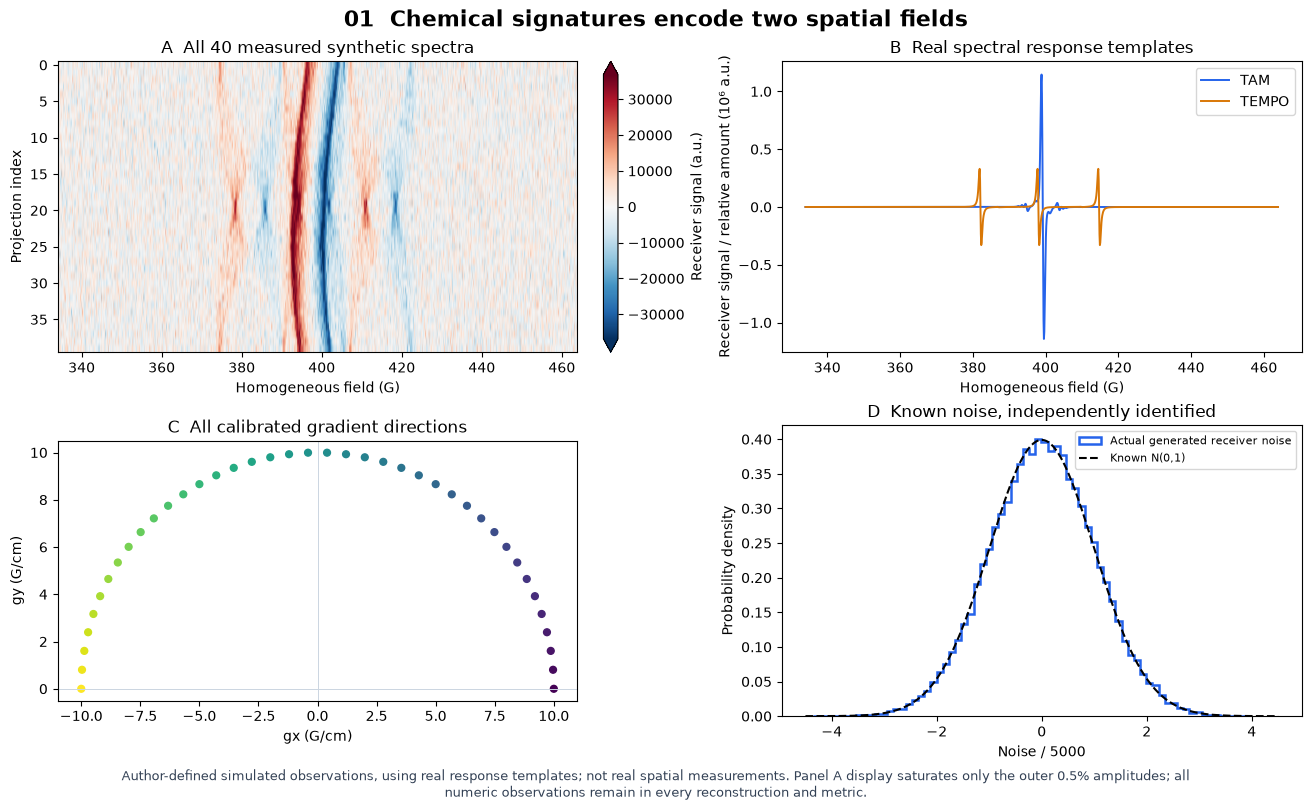

In [2]:
data=load_data(ROOT/'data/raw_data.npz')
print({key:dict(shape=value.shape,dtype=str(value.dtype)) for key,value in data.items()})
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as archive:
    reference={key:archive[key] for key in archive.files}
truth=reference['truth'][0]
source=reference['reconstruction'][0]
show_group('01_acquisition',visual.acquisition_figure(data,reference),
           dict(data,original_noise=reference['original_noise']))


# 3. Physics — signs, quadrature and independent controls

Let H be the unnormalized DFT of a supplied template, N the number of field channels, δ the spatial spacing and ΔB the first supplied field difference. The source discretization is

$$
Y_p[k]=T_{pk}\delta^2\sum_j H_j[k]\sum_{a,b}u_j[a,b]
\exp\left(\mathrm{i}\frac{2\pi k}{N\Delta B}
[g_{xp}\delta(b-50)+g_{yp}\delta(a-50)]\right).
$$

T retains k<N/2 and ||g||k<NΔB/(2δ). The positive phase implements h(B+g·r), and inverse real DFT supplies1/N. The adjoint halves DC before completing the missing negative frequencies as twice the real part. Cross-species kernels represent the complete A* A operator, not two separate inverse problems.

The following checks actively compare a known shifted positive point to an independent formula, direct versus FFT normal actions, Euclidean and TV adjoints, and finite differences of the true data objective. These controls do not establish truth accuracy on their own; the later known-truth/noise checks are separate.


In [3]:
physics_model=make_model(data)
normal=NormalOperator(physics_model.kernels(),physics_model.shape)
physics,physics_names=review_physics(physics_model,normal,data['projections'])
physics_limits=np.array([1e-10,1e-10,1e-10,1e-12,1e-5])
print(dict(zip(physics_names,physics['errors'].tolist())))
assert np.all(physics['errors']<=physics_limits)


{'Point shift': 1.137508054892877e-15, 'Adjoint dot': 5.655970751581712e-15, 'Toeplitz normal': 1.4700427794544644e-15, 'TV adjoint': 2.7715806788429764e-16, 'Objective derivative': 2.814521412434138e-10}


# 4. Method — coupled signed TV and actual reconstruction

The fixed author configuration minimizes

$$
E(u)=\tfrac12\|Au-s\|_2^2+W\sum_j\sum_{a,b}
\sqrt{(D_yu_j)^2+(D_xu_j)^2}.
$$

D is the nodal forward difference with zero outward boundary difference, and div=−D*. The normalized author λ=10 becomes

$$
W=\max_j(\max h_j-\min h_j)\frac{P}{2\pi}
\frac{N}{B_{N-1}-B_0}\delta\lambda .
$$

Initialize uj=(A*s)j divided by its spatial integral, then obtain Lf using power iteration on A* A with1.05 safety factor. The CP2016 primal/dual steps are τ=1/(2Lf) and σ=Lf/(8W²). Each dual vector is projected onto its pointwise unit ball; each primal update adds τ(W div(p)−(A*Au−A*s)); extrapolation is twice the new field minus the old field. There is no positivity projection in the primary. Stop at relative primal change below1e−5 or5000 updates.

First the actual standard CLI runs as a fresh child process. Then a second complete local reconstruction logs energy without changing arithmetic; its field must exactly equal the just-computed CLI output. Neither invocation loads the original reconstruction or truth.


{
  "command": [
    "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
    "-m",
    "src.main"
  ],
  "returncode": 0,
  "seconds": 3.3569462000159547,
  "stdout": "{\"seconds\": 3.213064600015059, \"iterations\": 1334, \"relative_update\": 9.97124147312974e-06, \"shape\": [1, 2, 100, 100]}\n",
  "stderr": "",
  "shell": false,
  "raw_sha256": "82da9130909870ab68dfef33e6ac29fd996116e5cbd683d01ffaefc0e04feb80"
}


Original/fresh relative L2: 1.2976111194192469e-12
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "TAM_ncc": 0.9798557718619909,
    "TAM_nrmse": 0.04729885151879676,
    "TAM_mass_relative_error": 0.07027345870399855,
    "TEMPO_ncc": 0.9877817607040029,
    "TEMPO_nrmse": 0.05565058790797031,
    "TEMPO_mass_relative_error": 0.010668133625782217,
    "forward_noise_rms_over_sigma": 0.9814851546586886,
    "absolute_residual_lag1": 0.03275245394692139,
    "forward_noise_rms_minimum_check": 0.9814851546586886,
    "forward_noise_rms_maximum_check": 0.9814851546586886
  },
  "thresholds": {
    "TAM_ncc": {
      "comparison": ">=",
      "boundary": 0.9
    },
    "TAM_nrmse": {
      "comparison": "<=",
      "boundary": 0.05202873667066663
    },
    "TAM_mass_relative_error": {
      "comparison": "<=",
      "boundary": 0.15
    },
    "TEMPO_ncc": {
      "comparison": ">=",
      "boundary": 0.9
    },
    "TEMPO_nrmse": {
      "comparison": "<=",
      "boundary": 

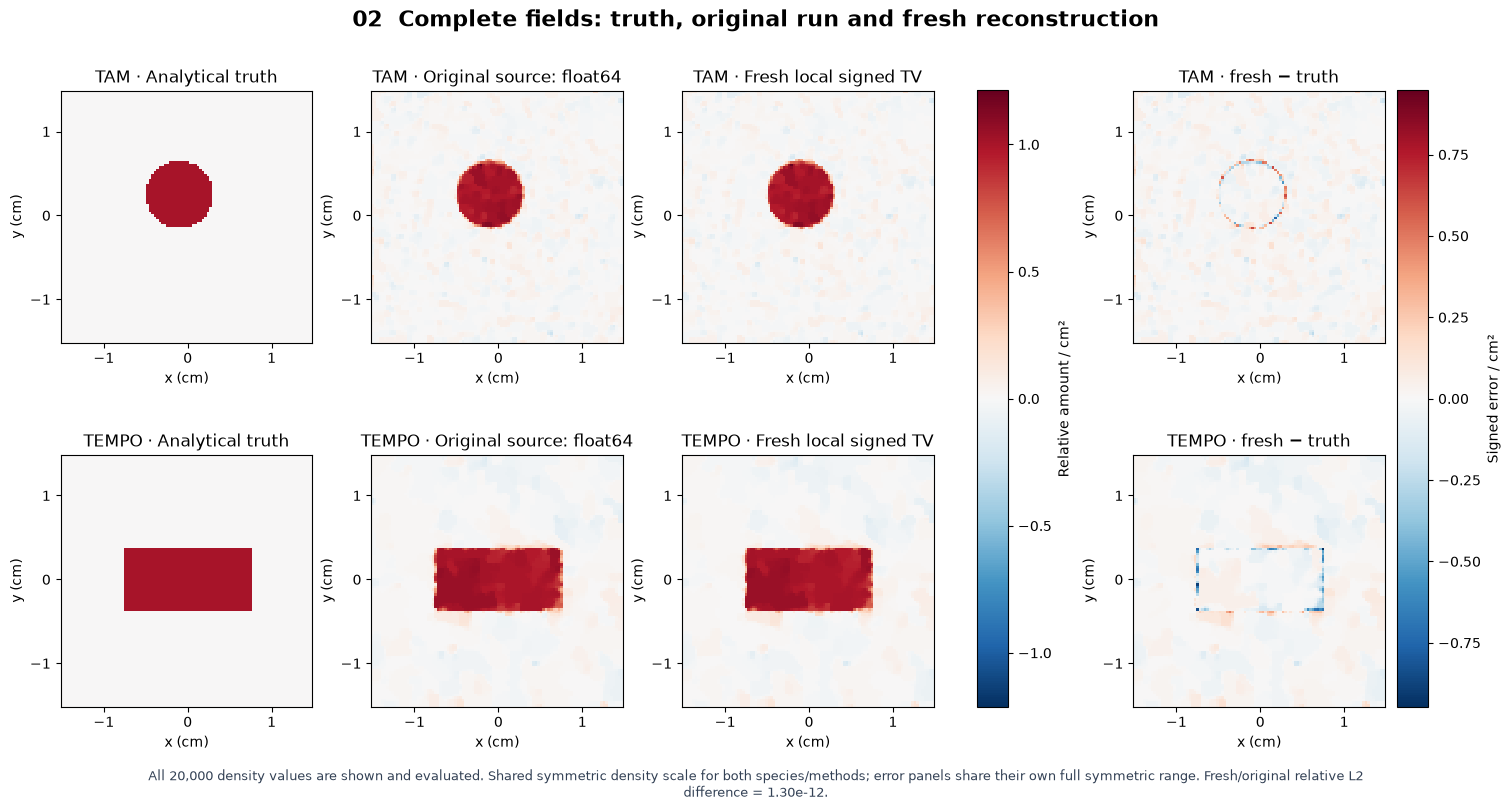

In [4]:
command=[sys.executable,'-m','src.main']
cli_started=time.perf_counter()
child=subprocess.run(command,cwd=ROOT,capture_output=True,text=True,shell=False)
cli_record=dict(command=command,returncode=child.returncode,seconds=time.perf_counter()-cli_started,
                stdout=child.stdout,stderr=child.stderr,shell=False,raw_sha256=raw_sha)
print(json.dumps(cli_record,indent=2))
assert child.returncode==0
with np.load(ROOT/'output/reconstruction.npz',allow_pickle=False) as archive:
    cli_field=archive['reconstruction'][0]
fresh,diagnostics=reconstruct(data['projections'],make_model(data),track_energy=True)
assert np.array_equal(fresh,cli_field)
source_relative_l2=float(np.linalg.norm(fresh-source)/np.linalg.norm(source))
assert source_relative_l2<=1e-7
judge_command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
judge_child=subprocess.run(judge_command,cwd=ROOT,capture_output=True,text=True,shell=False)
assert judge_child.returncode==0,(judge_child.stdout,judge_child.stderr)
judge_report=json.loads((ROOT/'output/judge_report.json').read_text())
assert judge_report['passed']
print('Original/fresh relative L2:',source_relative_l2)
print(json.dumps(judge_report,indent=2))
show_group('02_fields',visual.field_comparison_figure(truth,source,fresh),
           dict(truth=truth,original_source=source,fresh=fresh))


# 5. Results — comparisons, bias and robustness

The primary was fixed before local extraction. All methods below are newly computed: signed TV, native nonnegative TV, quarter/fourfold regularization, independent species fits and the original normalized backprojection initializer. Removing source coupling changes the ablation objective to a sum of separate fits of the same mixture. It is not mislabeled as the full published model.

Positivity is not automatically a better estimator of chemical amount: truncation of a large zero-density background can add net positive mass. We preserve the positive variant's failed15% TAM amount criterion, even when its pixelwise RMS is smaller.

Noise comparisons scale one known realization by0.5/1/2; they are not bootstrap coverage estimates. Angular comparisons use10/20/40 directions with the same complete spatial grid. Scientific metrics always use all20,000 density values, even where plot limits saturate displayed colors. The original demo's truth, both chemical images and mixture display are retained; the review adds explicit source/fresh, ablation and known-noise evidence.


Fresh method names: ['Signed TV (primary)', 'Nonnegative TV', 'Weak TV', 'Strong TV', 'Ignore source coupling', 'Normalized backprojection']
Metrics [method,species,(NCC,NRMSE,amount error)]:
[[[ 9.79855772e-01  4.72988515e-02  7.02734587e-02]
  [ 9.87781761e-01  5.56505879e-02  1.06681336e-02]]

 [[ 9.82972208e-01  4.37913204e-02  3.17634366e-01]
  [ 9.89982438e-01  5.12766601e-02  1.08463197e-01]]

 [[ 9.30255298e-01  9.11981747e-02  7.37631614e-02]
  [ 9.15441925e-01  1.55360350e-01  3.80139088e-03]]

 [[ 9.89828806e-01  3.35729800e-02  4.82996730e-02]
  [ 9.95348844e-01  4.62540929e-02  8.76151047e-02]]

 [[ 9.17159259e-01  1.21357013e-01  3.43288698e-01]
  [ 8.30366527e-01  2.79702307e-01  5.54112362e-01]]

 [[ 8.69042106e-01  3.85555076e+00  1.00924252e+00]
  [-5.57482594e-01  1.70285585e+00  1.28540305e-01]]]
Review seconds: 46.28624000001582


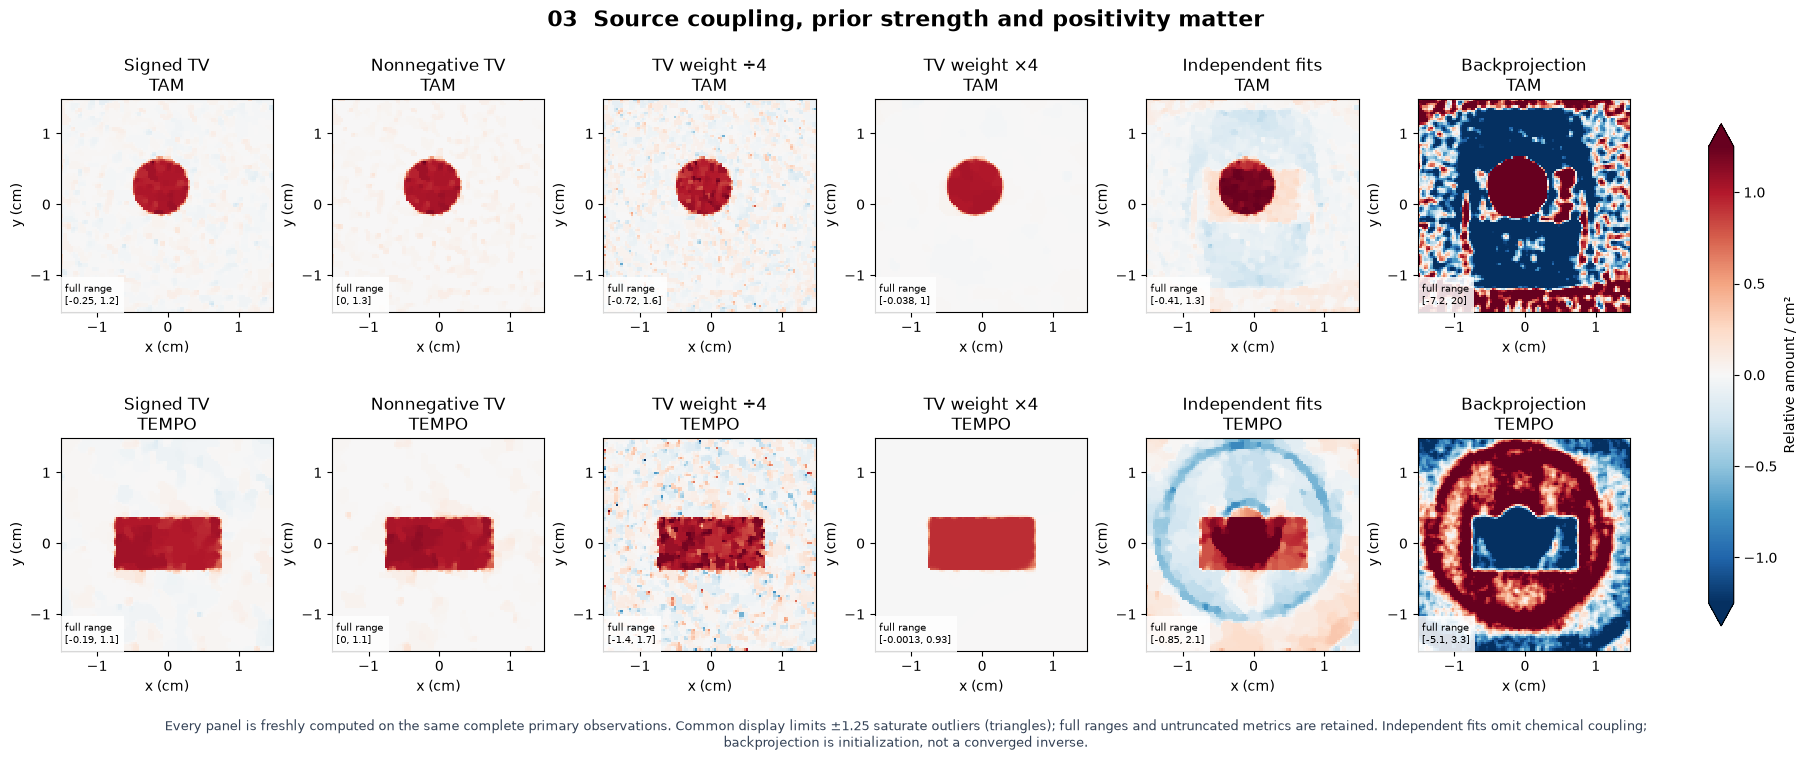

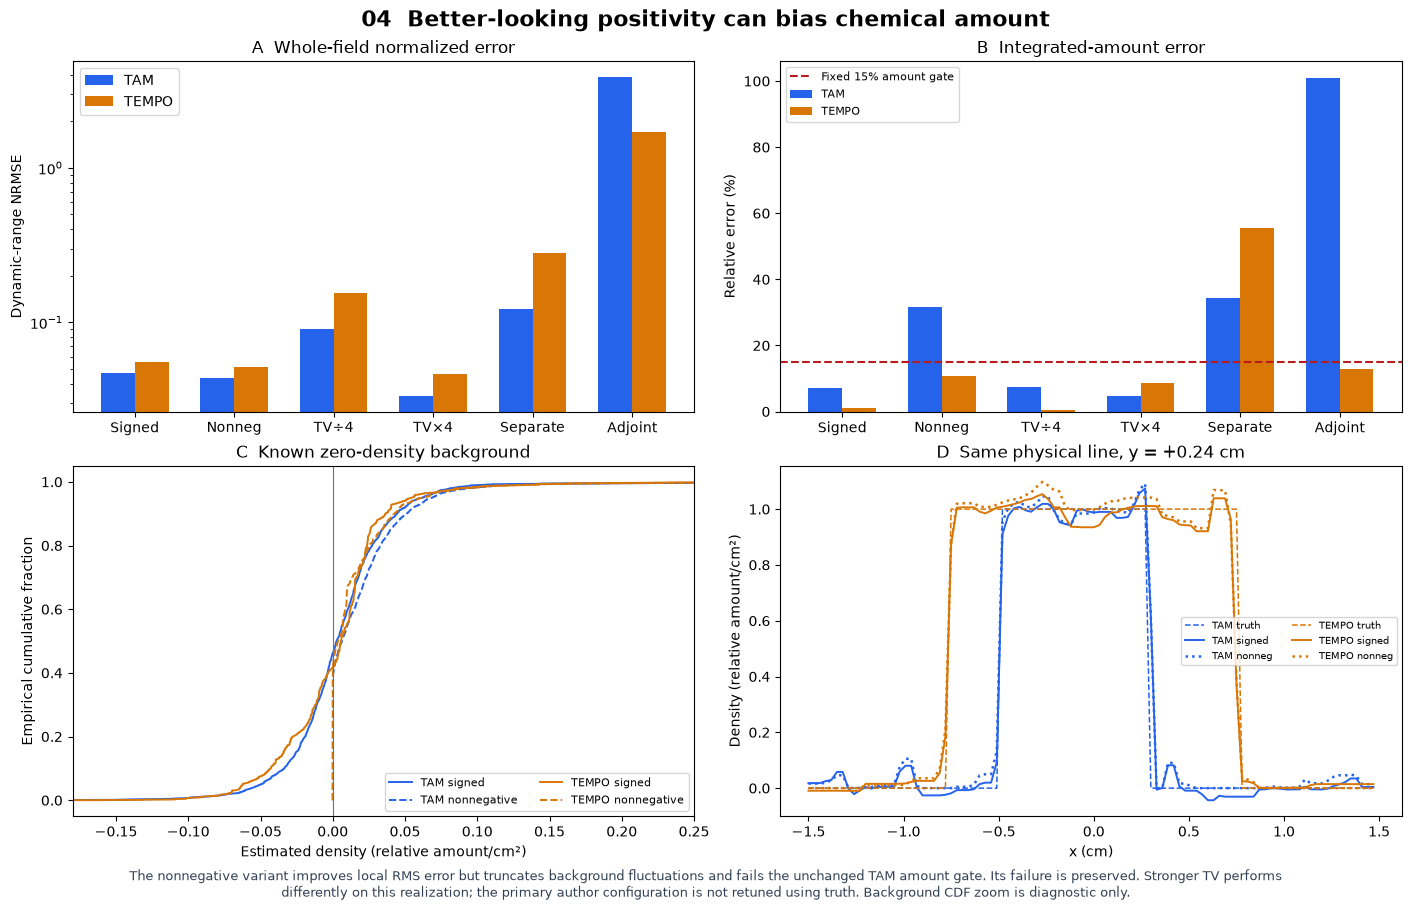

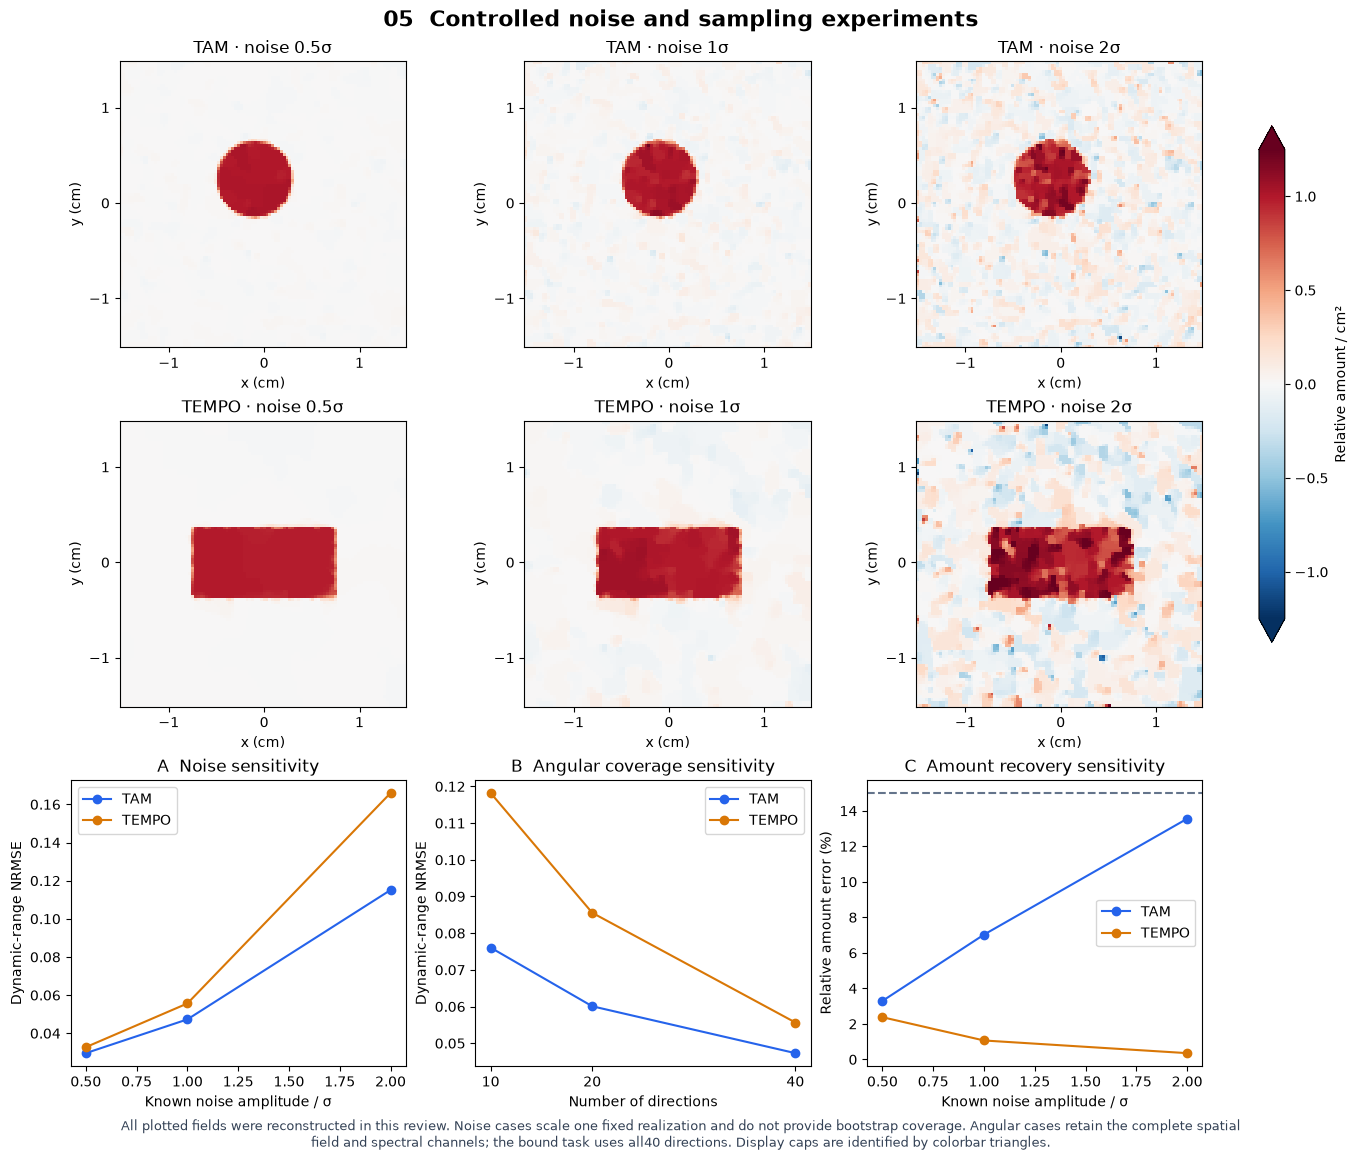

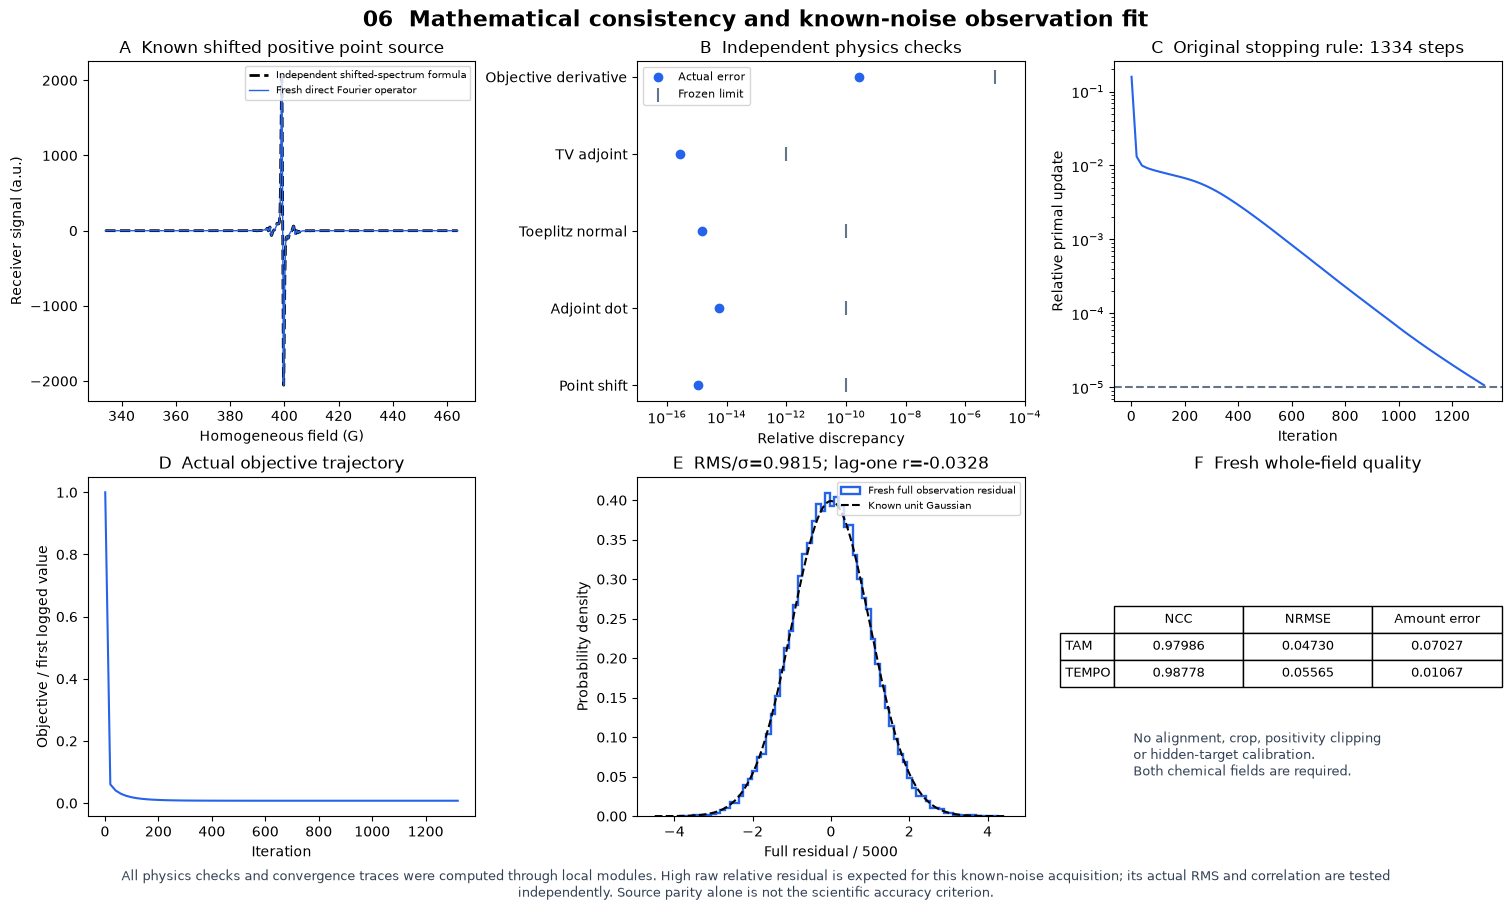

3771

In [5]:
review_started=time.perf_counter()
review,method_names=review_comparisons(data,fresh,diagnostics,truth,reference['clean_observations'])
review_seconds=time.perf_counter()-review_started
metrics=field_metrics(fresh,truth)
print('Fresh method names:',method_names)
print('Metrics [method,species,(NCC,NRMSE,amount error)]:')
print(review['method_metrics'])
print('Review seconds:',review_seconds)
assert np.all(metrics[:,0]>=.9) and np.all(metrics[:,1]<=.1) and np.all(metrics[:,2]<=.15)
assert review['method_metrics'][1,0,2]>.15
show_group('03_methods',visual.method_maps_figure(review,method_names),
           dict(method_reconstructions=review['method_reconstructions'],method_metrics=review['method_metrics']))
show_group('04_bias',visual.bias_and_metrics_figure(review,truth),
           dict(method_reconstructions=review['method_reconstructions'],method_metrics=review['method_metrics'],truth=truth))
show_group('05_sensitivity',visual.sensitivity_figure(review),
           {key:value for key,value in review.items() if key.startswith(('noise_','angular_'))})
show_group('06_physics',visual.physics_and_residuals_figure(data,fresh,diagnostics,physics,physics_names,metrics),
           dict(physics,history=diagnostics['history'],energy_history=diagnostics['energy_history'],
                fresh=fresh,observed=data['projections']))
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_review_measurements.npz',
                    fresh=fresh,**review,history=diagnostics['history'],
                    energy_history=diagnostics['energy_history'],physics_errors=physics['errors'])
execution=dict(metadata,cli=cli_record,judge_returncode=judge_child.returncode,
               original_fresh_relative_l2=source_relative_l2,
               fresh_metrics=metrics.tolist(),method_names=method_names,
               method_metrics=review['method_metrics'].tolist(),
               physics_names=physics_names,physics_errors=physics['errors'].tolist(),
               review_seconds=review_seconds,notebook_seconds_so_far=time.perf_counter()-started,
               reconstruction_sha256=hashlib.sha256((ROOT/'output/reconstruction.npz').read_bytes()).hexdigest(),
               comparison_roles={'source':'Independent exact-bound original float64 run before local',
                                 'fresh':'Computed here through local modules',
                                 'truth':'Analytical author-defined physical fields',
                                 'positive':'Fresh native optional constraint; failed TAM amount gate preserved'})
(ROOT/'notebooks/reference_outputs/fresh_execution.json').write_text(json.dumps(execution,indent=2,allow_nan=False),encoding='utf-8')


# 6. Conclusion — what this experiment establishes

The two chemical fields are recovered with their own spatial and integrated-amount checks. Full direct-Fourier/FFT source parity, independent point/adjoint/gradient controls and known-noise residual statistics support the selected signed estimator on this fixed simulated experiment. A smaller-looking local RMS alone does not justify discarding an amount-bias failure.

This is not a claim of experimental absolute radical concentration or universal accuracy on arbitrary real acquisitions. The real spectral templates provide relative signatures; finite angular coverage, discretization, noise and regularization remain limitations. The failed real-data screening and failed positive variant are not silently relabeled as successes. No hidden spatial calibration or truth is used by the primary inverse.

References: Abergel, Durand and Frapart, Journal of Magnetic Resonance376:107891(2025), DOI10.1016/j.jmr.2025.107891; Boussâa et al., Journal of Magnetic Resonance357:107583(2023), DOI10.1016/j.jmr.2023.107583; Chambolle and Pock, Mathematical Programming159:253–287(2016), DOI10.1007/s10107-015-0957-3. The specific original synthetic source and explicit numerical parameter variant are indexed in validation.md.


In [6]:
display(Markdown(
    f'Fresh full fields: TAM NCC **{metrics[0,0]:.4f}**, NRMSE **{metrics[0,1]:.4f}**, amount error **{100*metrics[0,2]:.2f}%**; '
    f'TEMPO NCC **{metrics[1,0]:.4f}**, NRMSE **{metrics[1,1]:.4f}**, amount error **{100*metrics[1,2]:.2f}%**. '
    f'The nonnegative TAM amount error is **{100*review["method_metrics"][1,0,2]:.2f}%**, above the fixed15% gate. '
    f'All values above were computed, not inserted as historical paper results.'))


Fresh full fields: TAM NCC **0.9799**, NRMSE **0.0473**, amount error **7.03%**; TEMPO NCC **0.9878**, NRMSE **0.0557**, amount error **1.07%**. The nonnegative TAM amount error is **31.76%**, above the fixed15% gate. All values above were computed, not inserted as historical paper results.